# LFM model finalization

The purpose of this notebook is to pick the best weights for the image-to-image generative model along with the number of steps in the diffusion/flow process.

## Setup

In [1]:
import os
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import pandas as pd
import torch
from monai.transforms import (
    CenterSpatialCropd,
    Compose,
    EnsureChannelFirstd,
    EnsureTyped,
    Lambdad,
    LoadImaged,
    Orientationd,
    SpatialPadd,
)

<frozen importlib._bootstrap_external>:1301: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.


In [2]:
# Find project root (folder that contains .git)
ROOT = Path.cwd()
while not (ROOT / ".git").exists():
    ROOT = ROOT.parent

# Set working directory to root
os.chdir(ROOT)

print("Now working in:", Path.cwd())

Now working in: /home/couch/Repos/robust-radiotherapy-planning


In [3]:
from src.data_utils import create_data_split_dict
from src.pipeline.cli import run_stage
from src.pipeline.config import MaisiTestingConfig
from src.pipeline.helpers.helpers_general import load_tensor

In [4]:
DUMMY_CONFIG = MaisiTestingConfig()

CHECKPOINT_DIR = Path("RESULTS/weights/diff_unet")
CTS_PER_PATIENT = 5
DEFAULT_STEPS = 30
EPOCHS_TO_TEST = [i for i in range(499, 5000, 500)]
MODEL_OUTPUT_DIR = Path("RESULTS/model_selection")

NUMBER_OF_STEPS = [10, 20, 30, 50, 80]
STEPS_OUTPUT_DIR = Path("RESULTS/step_selection")

In [5]:
# Function to be used for extracting a shorter metric summary
def get_mean_of_means(csv_path, name):
    # Load CSV with 2-level column headers and patient_id as row index
    df = pd.read_csv(csv_path, header=[0, 1], index_col=0)

    # Cross-section level 1 for 'mean' columns and calculate the mean across patients
    mean_series = df.xs("mean", level=1, axis=1).mean()

    # Set the Series name
    mean_series.name = name

    return mean_series

In [6]:
# Preparation and encoding do not depend on the model or steps
run_stage(MaisiTestingConfig(evaluation_split="val", stage="prepare"))
run_stage(MaisiTestingConfig(evaluation_split="val", stage="encode"))

Encoding planning CTs: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11/11 [00:35<00:00,  3.22s/it]


## Post-processing investigation

It is clear that the generated CT scans should be rounded to integers, but due to the nature of diffussion and diffusion-like models, some noise may remain for areas which are pure air. It would make sense to consider all values below -950 to be air and round them down all the way to -1000 to ensure air is uniform. This section aims to check whether this step actually makes the CTs more similar to real ones or not. It is possible that there is real scanner noise in which case, this step should not be done.

In [7]:
# Load data dictionaries
data_dict = create_data_split_dict(
    seed=42,
    train_fraction=0.8,
    folds=5,
    save=False,
)
print(str(data_dict[0]["val"])[:200])

['/home/couch/Repos/robust-radiotherapy-planning/src/data_full/CT/Patient_56/Patient_56_fraction_10_.nii.gz', '/home/couch/Repos/robust-radiotherapy-planning/src/data_full/CT/Patient_56/Patient_56_fra


In [8]:
transform = Compose(
    [
        LoadImaged(keys="image"),
        EnsureChannelFirstd(keys="image"),
        Orientationd(keys="image", axcodes="RAS", labels=None),
        Lambdad(
            keys="image",
            func=lambda x: torch.clamp(x, min=DUMMY_CONFIG.data_min, max=DUMMY_CONFIG.data_max),
        ),
        SpatialPadd(
            keys="image",
            spatial_size=DUMMY_CONFIG.target_image_size,
            mode="constant",
            constant_values=DUMMY_CONFIG.data_min,
        ),
        CenterSpatialCropd(keys="image", roi_size=DUMMY_CONFIG.target_image_size),
        EnsureTyped(keys="image", dtype=torch.float32),
    ]
)

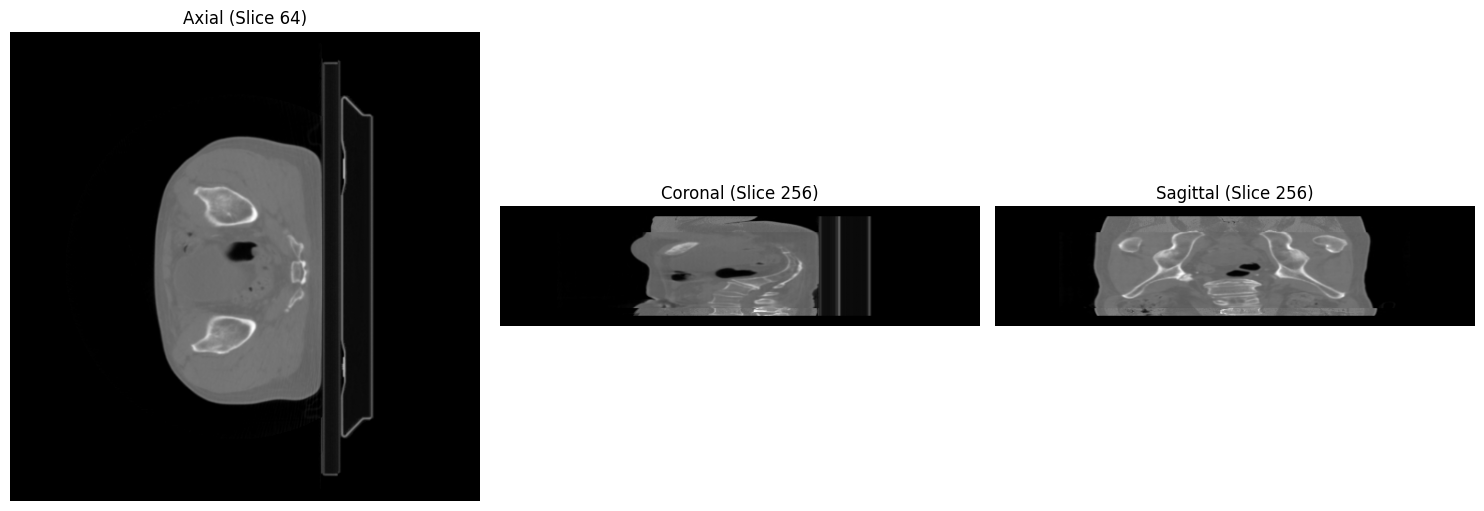

In [9]:
# Process an example image
img_path = data_dict[0]["val"][0]
img_nib = nib.load(img_path)

image_dict = {"image": img_path}
transformed_dict = transform(image_dict)
img_tensor = transformed_dict["image"]

# Matplotlib handles 32-bit float better
img_array = img_tensor.detach().cpu().float().numpy()

# Squeeze the channel dimension (C, H, W, D) -> (H, W, D)
img_array = img_array[0]

# Get middle indices for each axis
idx_h, idx_w, idx_d = [s // 2 for s in img_array.shape]

# Create the plot
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Axial view (Top-down)
axes[0].imshow(img_array[:, :, idx_d].T, cmap="gray", origin="lower")
axes[0].set_title(f"Axial (Slice {idx_d})")
axes[0].axis("off")

# Coronal view (Front-to-back)
axes[1].imshow(img_array[:, idx_w, :].T, cmap="gray", origin="lower")
axes[1].set_title(f"Coronal (Slice {idx_w})")
axes[1].axis("off")

# Sagittal view (Side-to-side)
axes[2].imshow(img_array[idx_h, :, :].T, cmap="gray", origin="lower")
axes[2].set_title(f"Sagittal (Slice {idx_h})")
axes[2].axis("off")

plt.tight_layout()
plt.show()

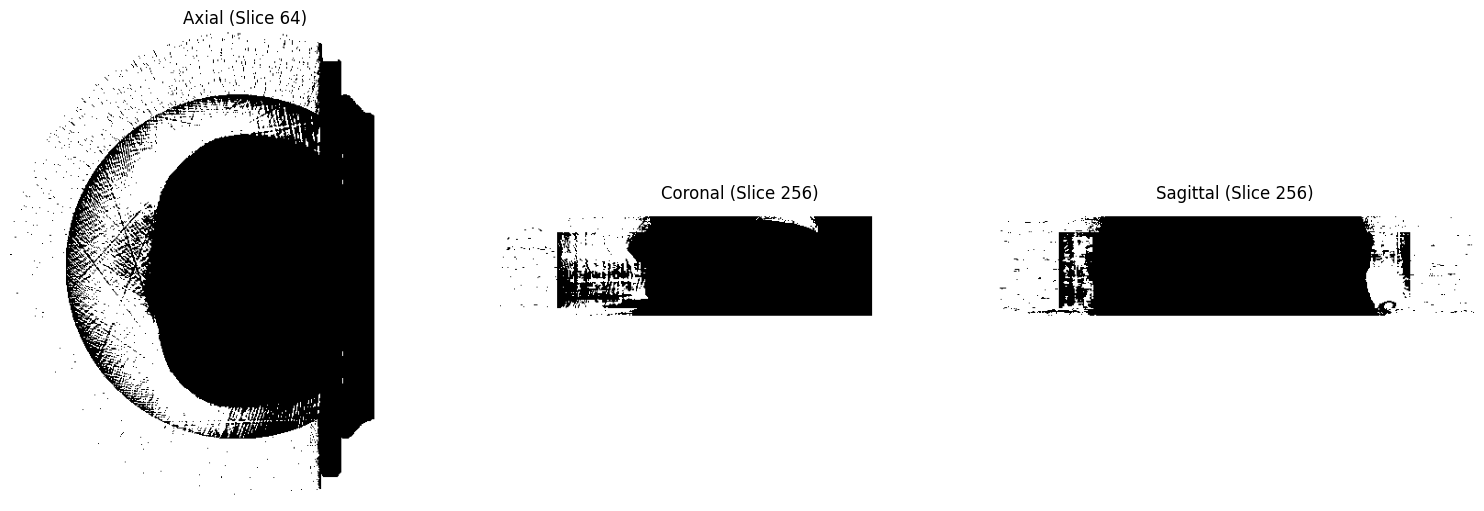

In [10]:
# Process an example image
img_path = data_dict[0]["val"][0]
img_nib = nib.load(img_path)

image_dict = {"image": img_path}
transformed_dict = transform(image_dict)
img_tensor = transformed_dict["image"]

# Matplotlib handles 32-bit float better
img_array = img_tensor.detach().cpu().float().numpy()

# Squeeze the channel dimension (C, H, W, D) -> (H, W, D) and turn into the desired boolean mask
img_array = img_array[0] == -1000.0

# Get middle indices for each axis
idx_h, idx_w, idx_d = [s // 2 for s in img_array.shape]

# Create the plot
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Axial view (Top-down)
axes[0].imshow(img_array[:, :, idx_d].T, cmap="gray", origin="lower")
axes[0].set_title(f"Axial (Slice {idx_d})")
axes[0].axis("off")

# Coronal view (Front-to-back)
axes[1].imshow(img_array[:, idx_w, :].T, cmap="gray", origin="lower")
axes[1].set_title(f"Coronal (Slice {idx_w})")
axes[1].axis("off")

# Sagittal view (Side-to-side)
axes[2].imshow(img_array[idx_h, :, :].T, cmap="gray", origin="lower")
axes[2].set_title(f"Sagittal (Slice {idx_h})")
axes[2].axis("off")

plt.tight_layout()
plt.show()

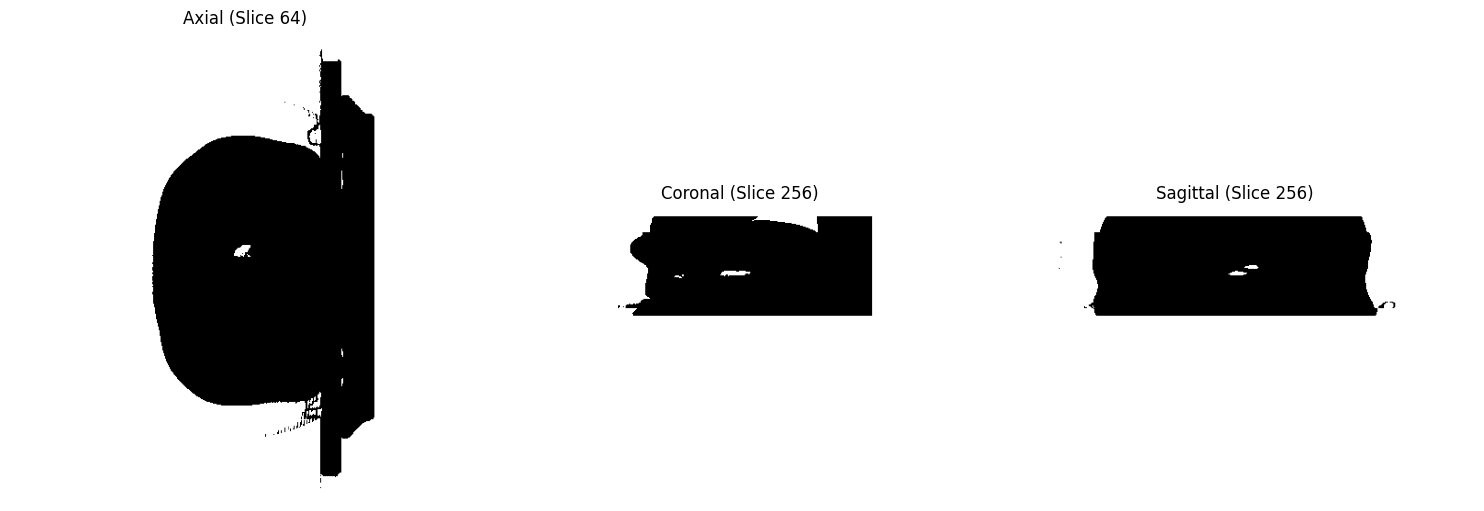

In [11]:
# Process an example image
img_path = data_dict[0]["val"][0]
img_nib = nib.load(img_path)

image_dict = {"image": img_path}
transformed_dict = transform(image_dict)
img_tensor = transformed_dict["image"]

# Matplotlib handles 32-bit float better
img_array = img_tensor.detach().cpu().float().numpy()

# Squeeze the channel dimension (C, H, W, D) -> (H, W, D) and turn into the desired boolean mask
img_array = img_array[0] < -950.0

# Get middle indices for each axis
idx_h, idx_w, idx_d = [s // 2 for s in img_array.shape]

# Create the plot
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Axial view (Top-down)
axes[0].imshow(img_array[:, :, idx_d].T, cmap="gray", origin="lower")
axes[0].set_title(f"Axial (Slice {idx_d})")
axes[0].axis("off")

# Coronal view (Front-to-back)
axes[1].imshow(img_array[:, idx_w, :].T, cmap="gray", origin="lower")
axes[1].set_title(f"Coronal (Slice {idx_w})")
axes[1].axis("off")

# Sagittal view (Side-to-side)
axes[2].imshow(img_array[idx_h, :, :].T, cmap="gray", origin="lower")
axes[2].set_title(f"Sagittal (Slice {idx_h})")
axes[2].axis("off")

plt.tight_layout()
plt.show()

It can clearly be seen that air is not actually a uniform -1000 or lower, so enforcing that rule on the generated CTs is articial and should not be done.

## Picking the best weights

The weights were saved regularly during training, so the best model can be picked from epochs:
- 499,
- 999,
- ...
- 4999\.

This is decided according to basic image metrics (mean of patient means) as well as visual inspection of generated CTs. For simplicity, visual inspection will be restricted to the first patient from the validation set.

In [12]:
for epoch in EPOCHS_TO_TEST:
    print("-" * 100)
    out_dir = MODEL_OUTPUT_DIR / str(epoch)

    # Skip iteration if output directory already exists
    if out_dir.exists():
        print(f"Skipping {epoch}: output directory '{out_dir}' already exists")
        continue

    print(f"Running {epoch}:")

    # Run just generation and evaluation
    path_overrides = {
        "rflow_weight_path": CHECKPOINT_DIR / f"epoch_{epoch}.pt",
    }
    generate_config = MaisiTestingConfig(
        evaluation_split="val",
        cts_per_patient=CTS_PER_PATIENT,
        steps=DEFAULT_STEPS,
        path_overrides=path_overrides,
        stage="generate",
    )
    run_stage(generate_config)
    evaluate_config = MaisiTestingConfig(
        evaluation_split="val",
        use_structure_metrics=False,
        use_dose_metrics=False,
        stage="evaluate",
    )
    run_stage(evaluate_config)

    # Copy results to the out location only after the run is complete
    shutil.copytree(generate_config.generated_ct_dir, out_dir / "generated_ct")
    shutil.copytree(evaluate_config.metrics_dir, out_dir / "metrics")

----------------------------------------------------------------------------------------------------
Skipping 499: output directory 'RESULTS/model_selection/499' already exists
----------------------------------------------------------------------------------------------------
Skipping 999: output directory 'RESULTS/model_selection/999' already exists
----------------------------------------------------------------------------------------------------
Skipping 1499: output directory 'RESULTS/model_selection/1499' already exists
----------------------------------------------------------------------------------------------------
Skipping 1999: output directory 'RESULTS/model_selection/1999' already exists
----------------------------------------------------------------------------------------------------
Skipping 2499: output directory 'RESULTS/model_selection/2499' already exists
----------------------------------------------------------------------------------------------------
Skipping

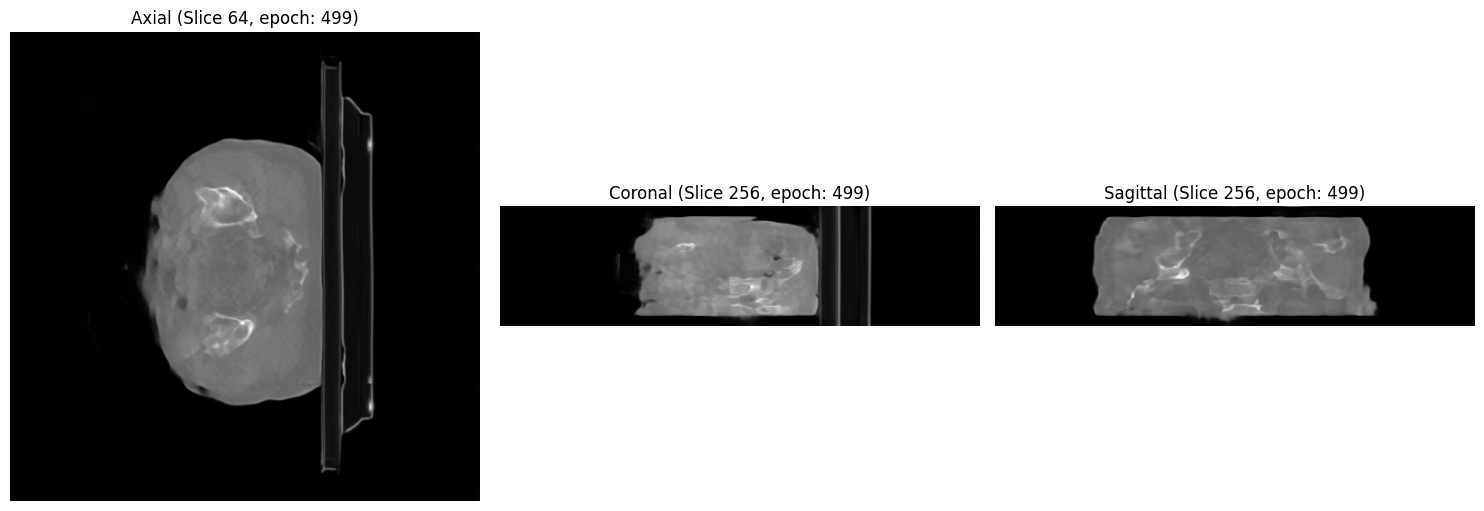

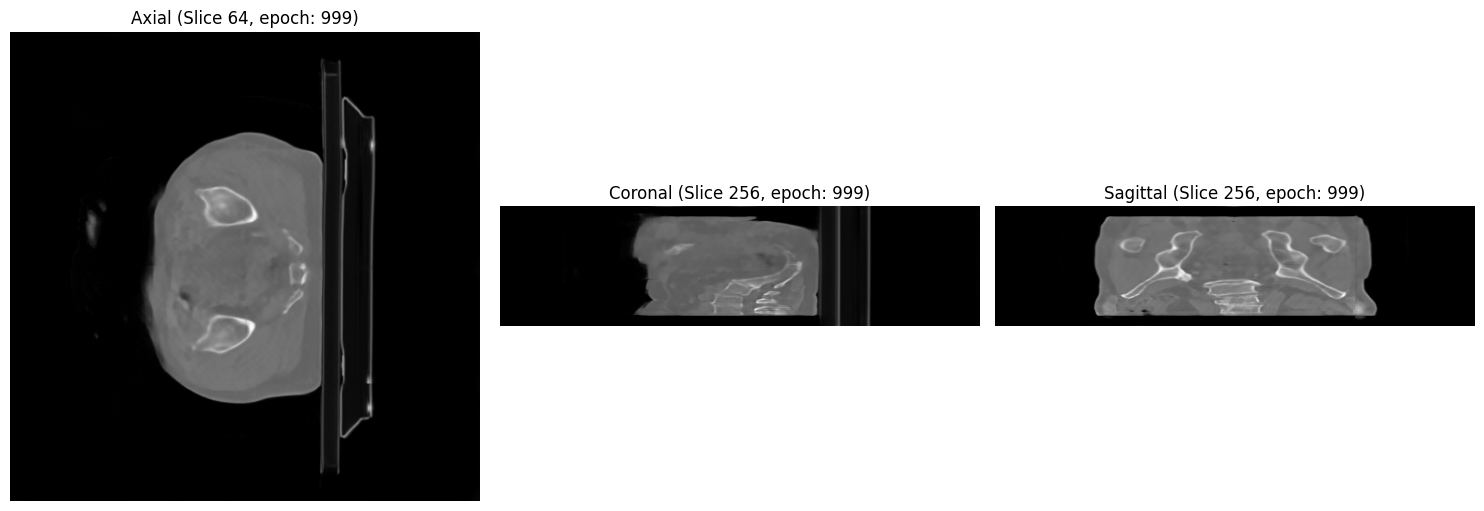

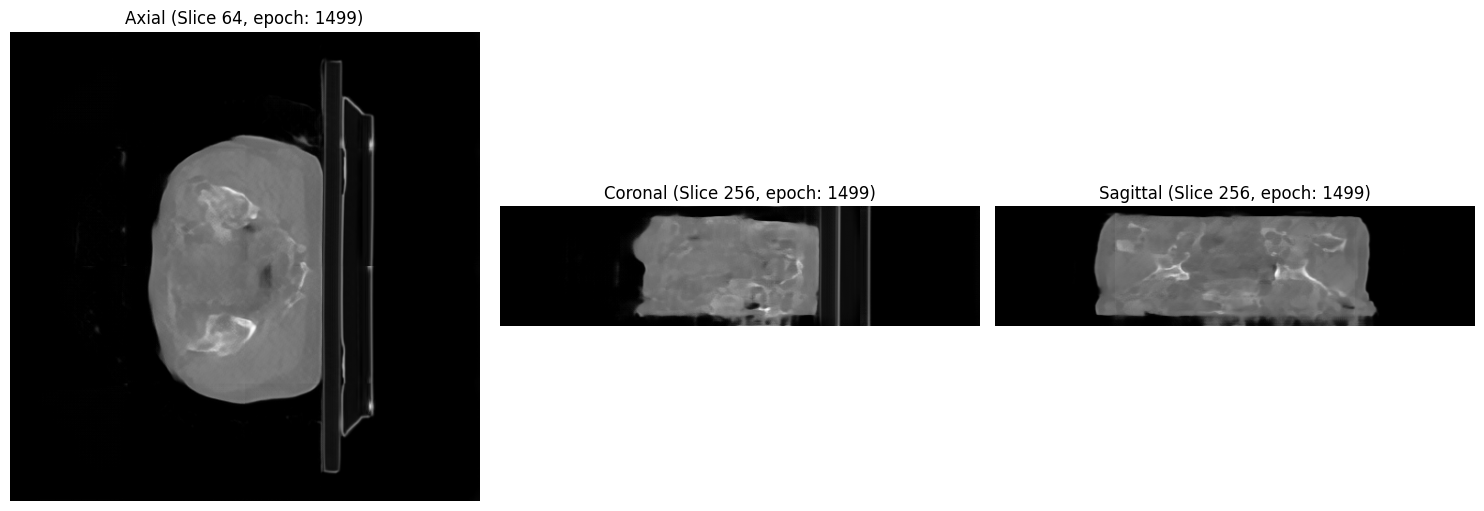

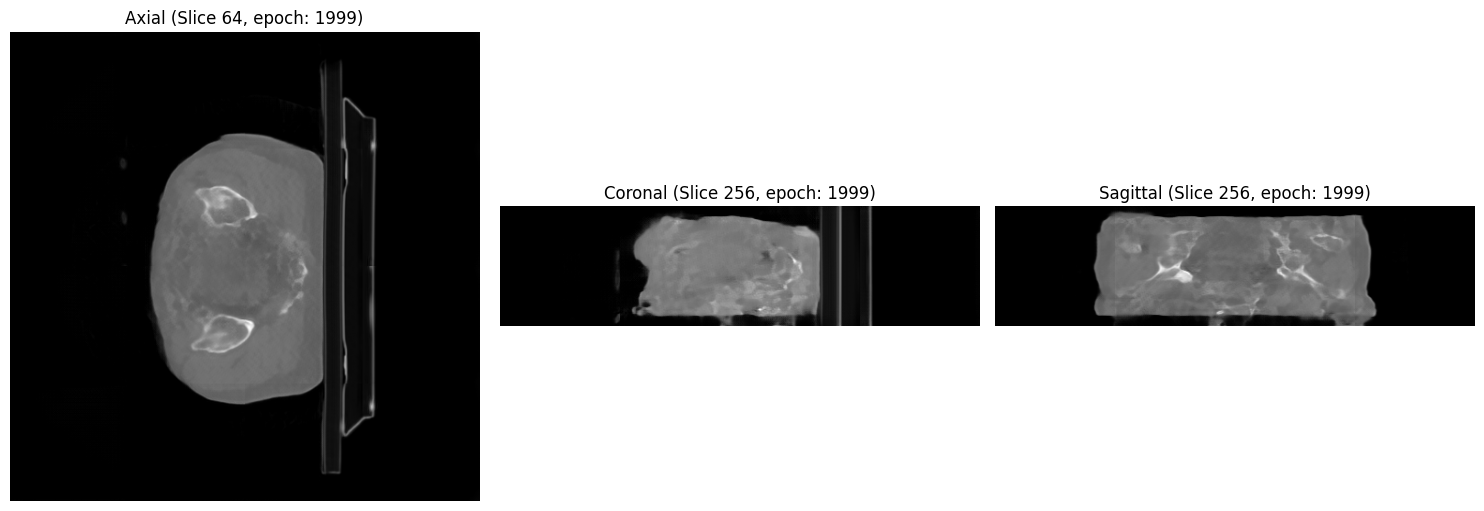

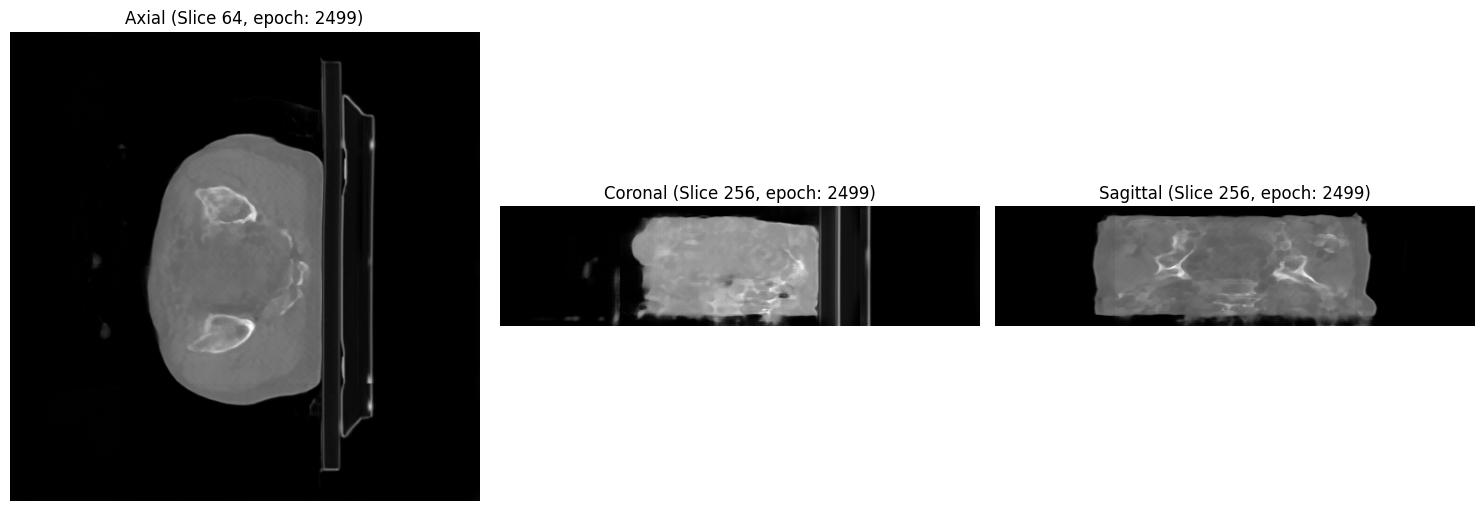

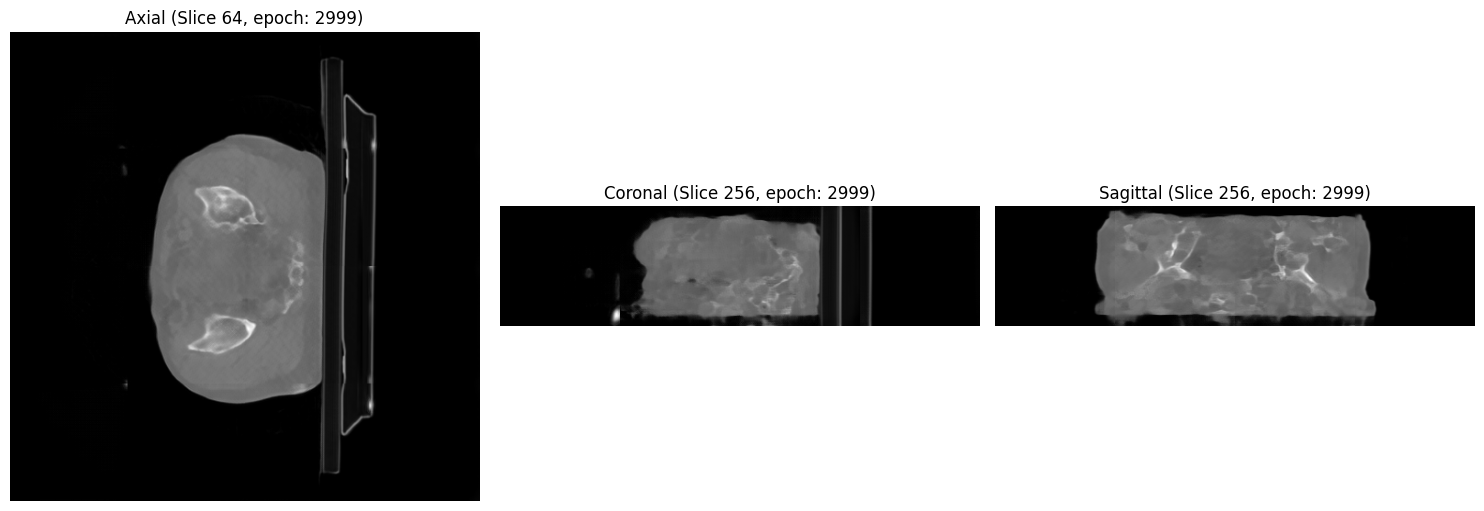

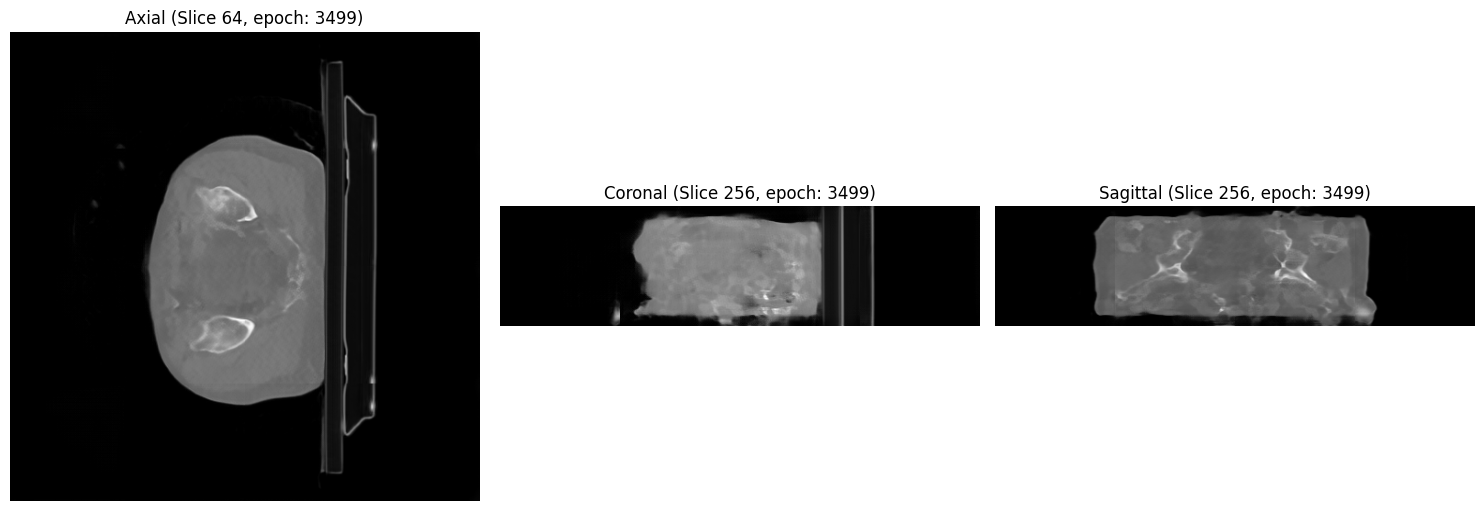

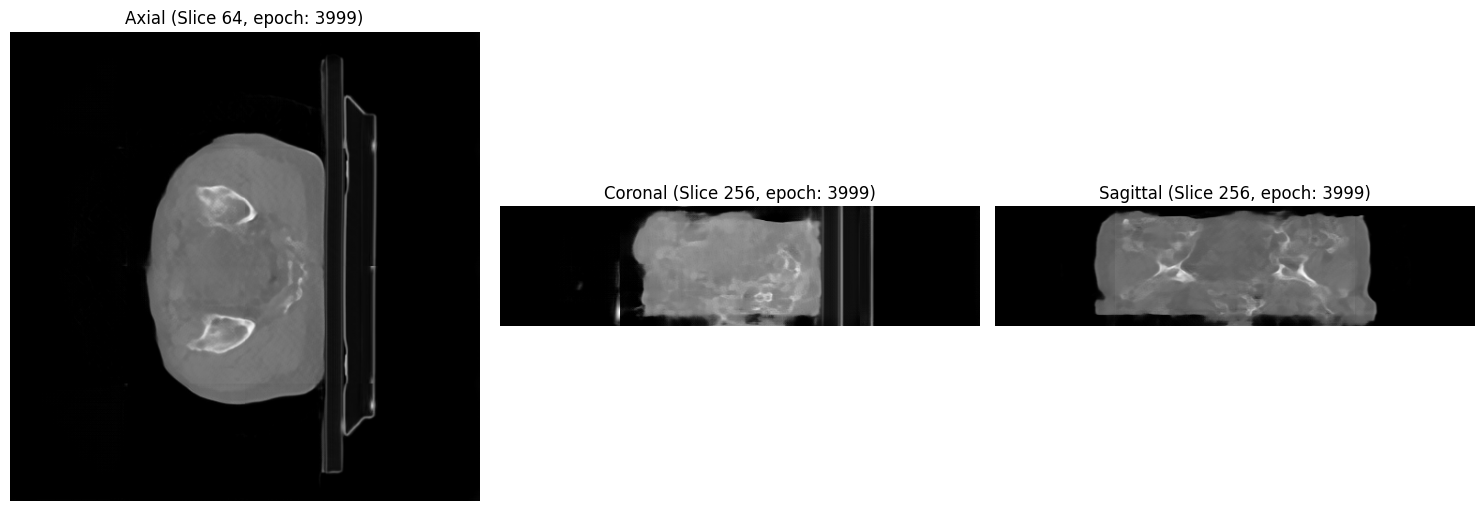

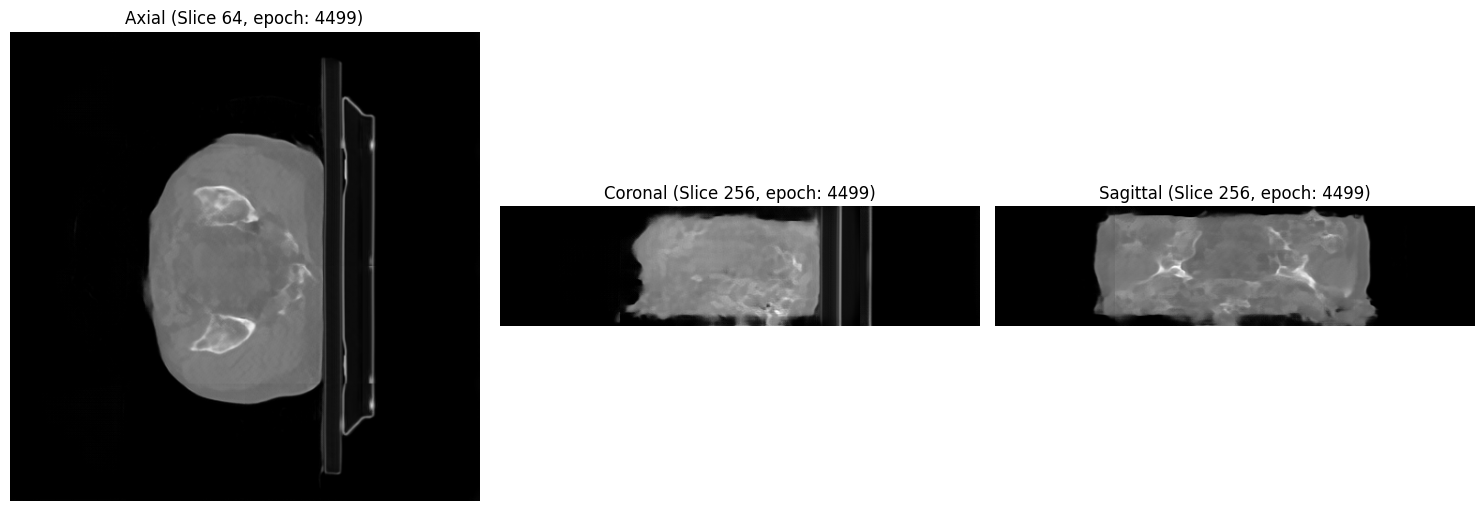

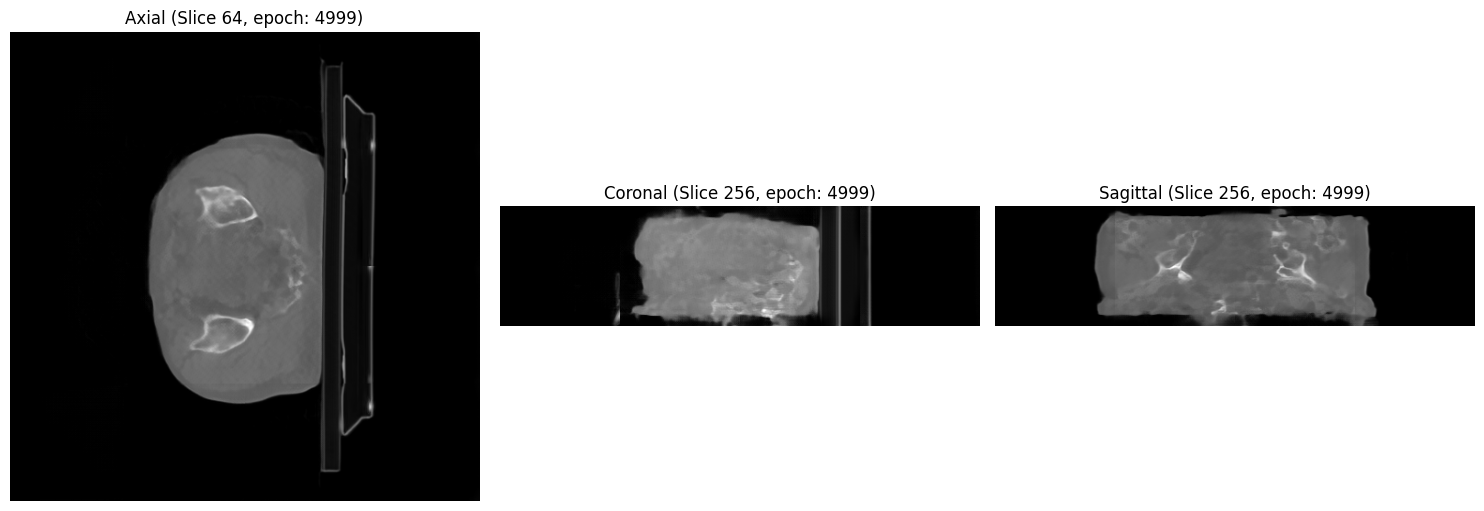

Generated vs Real:


,499,999,1499,1999,2499,2999,3499,3999,4499,4999
mae,34.252992,34.301220,35.679905,36.320424,36.285709,36.923894,37.246681,38.039465,38.120788,38.012218
ssim,0.842271,0.845014,0.840604,0.838527,0.838562,0.837058,0.834832,0.832219,0.831528,0.831954
psnr,27.173471,27.129393,26.840864,26.656442,26.662533,26.560043,26.490103,26.347704,26.294974,26.345834
sob,466.054158,470.253016,483.327470,490.177112,490.902731,495.652615,499.030875,507.703791,508.267611,506.311835
lpips,0.114077,0.109952,0.114822,0.115866,0.115509,0.116801,0.117838,0.119378,0.119720,0.119717


Pairwise:


,499,999,1499,1999,2499,2999,3499,3999,4499,4999
mae,19.625475,18.676134,18.584576,18.801055,18.092811,17.983702,18.360530,19.476451,19.594425,18.424690
ssim,0.914052,0.922325,0.923310,0.923325,0.927412,0.928289,0.925798,0.920942,0.919909,0.925678
psnr,31.050847,31.247495,31.364926,31.327486,31.549184,31.558606,31.497726,31.206877,31.152883,31.471265
sob,299.585487,292.692395,288.943403,290.470720,281.414685,279.769156,286.440226,299.813155,300.040339,284.892714
lpips,0.055503,0.048351,0.045334,0.045801,0.043471,0.042496,0.043005,0.045797,0.045801,0.044802


In [13]:
generated_vs_real_columns = []
pairwise_columns = []
for epoch in EPOCHS_TO_TEST:
    out_dir = MODEL_OUTPUT_DIR / str(epoch)

    # Create two series of summary metrics
    generated_vs_real_columns.append(
        get_mean_of_means(out_dir / "metrics" / "generated_vs_real_summary.csv", str(epoch))
    )
    pairwise_columns.append(
        get_mean_of_means(out_dir / "metrics" / "generated_pairwise_variety_metrics_summary.csv", str(epoch))
    )

    # Get a generated CT for the same patient in the first section
    generated_img = load_tensor(out_dir / "generated_ct" / "Patient_56" / "Patient_56_gen_1.pt")

    # Get middle indices for each axis
    idx_h, idx_w, idx_d = [s // 2 for s in generated_img.shape]

    # Create the plot
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Axial view (Top-down)
    axes[0].imshow(generated_img[:, :, idx_d].T, cmap="gray", origin="lower")
    axes[0].set_title(f"Axial (Slice {idx_d}, epoch: {epoch})")
    axes[0].axis("off")

    # Coronal view (Front-to-back)
    axes[1].imshow(generated_img[:, idx_w, :].T, cmap="gray", origin="lower")
    axes[1].set_title(f"Coronal (Slice {idx_w}, epoch: {epoch})")
    axes[1].axis("off")

    # Sagittal view (Side-to-side)
    axes[2].imshow(generated_img[idx_h, :, :].T, cmap="gray", origin="lower")
    axes[2].set_title(f"Sagittal (Slice {idx_h}, epoch: {epoch})")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

generated_vs_real_epoch_df = pd.concat(generated_vs_real_columns, axis=1)
pairwise_epoch_df = pd.concat(pairwise_columns, axis=1)

print("Generated vs Real:")
display(generated_vs_real_epoch_df)
print("Pairwise:")
display(pairwise_epoch_df)

The best checkpoint seems to be the last one, but the different is pretty minimal as the general patterns are learned within the first 500 epochs. The metrics mostly indicate a performance decrease, but that is not actually true. Higher epochs significantly reduce artefacts. 

## Picking the best flow steps

After picking the best model it is also important to check if the default 30 rectified flow steps are good.

In [14]:
best_weight_path = CHECKPOINT_DIR / "epoch_4999.pt"

In [15]:
for steps in NUMBER_OF_STEPS:
    print("-" * 100)
    out_dir = STEPS_OUTPUT_DIR / str(steps)

    # Skip iteration if output directory already exists
    if out_dir.exists():
        print(f"Skipping {steps}: output directory '{out_dir}' already exists")
        continue

    print(f"Running {steps}:")

    # Run just generation and evaluation
    path_overrides = {
        "rflow_weight_path": best_weight_path,
    }
    generate_config = MaisiTestingConfig(
        evaluation_split="val",
        cts_per_patient=CTS_PER_PATIENT,
        steps=steps,
        path_overrides=path_overrides,
        stage="generate",
    )
    run_stage(generate_config)
    evaluate_config = MaisiTestingConfig(
        evaluation_split="val",
        use_structure_metrics=False,
        use_dose_metrics=False,
        stage="evaluate",
    )
    run_stage(evaluate_config)

    # Copy results to the out location only after the run is complete
    shutil.copytree(generate_config.generated_ct_dir, out_dir / "generated_ct")
    shutil.copytree(evaluate_config.metrics_dir, out_dir / "metrics")

----------------------------------------------------------------------------------------------------
Skipping 10: output directory 'RESULTS/step_selection/10' already exists
----------------------------------------------------------------------------------------------------
Skipping 20: output directory 'RESULTS/step_selection/20' already exists
----------------------------------------------------------------------------------------------------
Skipping 30: output directory 'RESULTS/step_selection/30' already exists
----------------------------------------------------------------------------------------------------
Skipping 50: output directory 'RESULTS/step_selection/50' already exists
----------------------------------------------------------------------------------------------------
Skipping 80: output directory 'RESULTS/step_selection/80' already exists


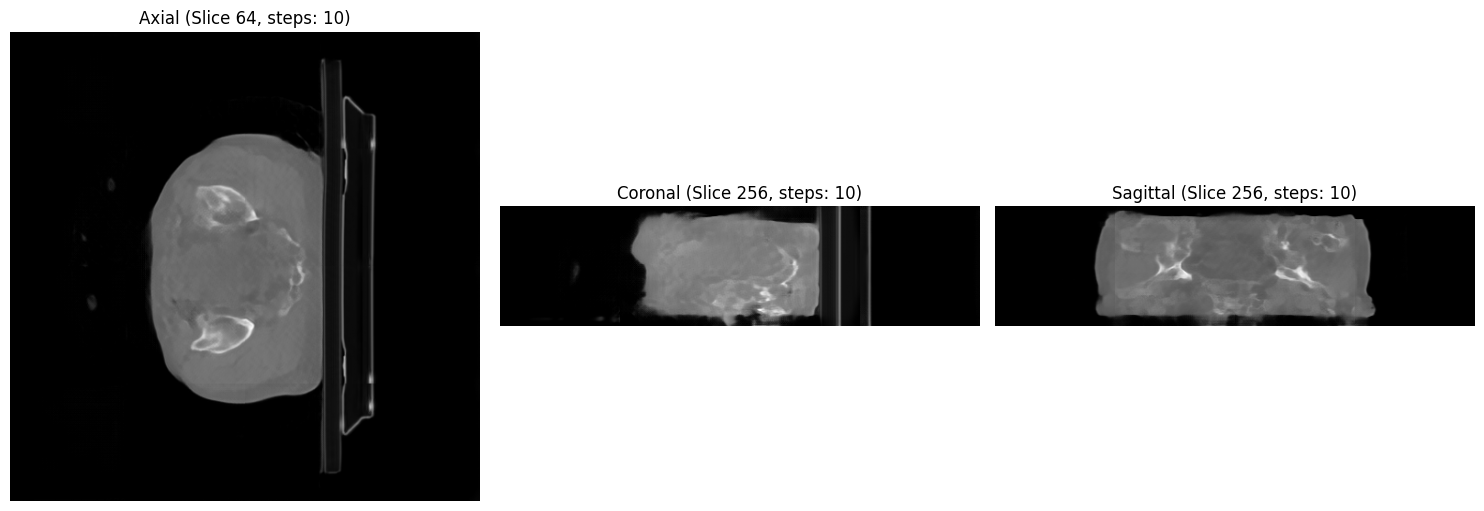

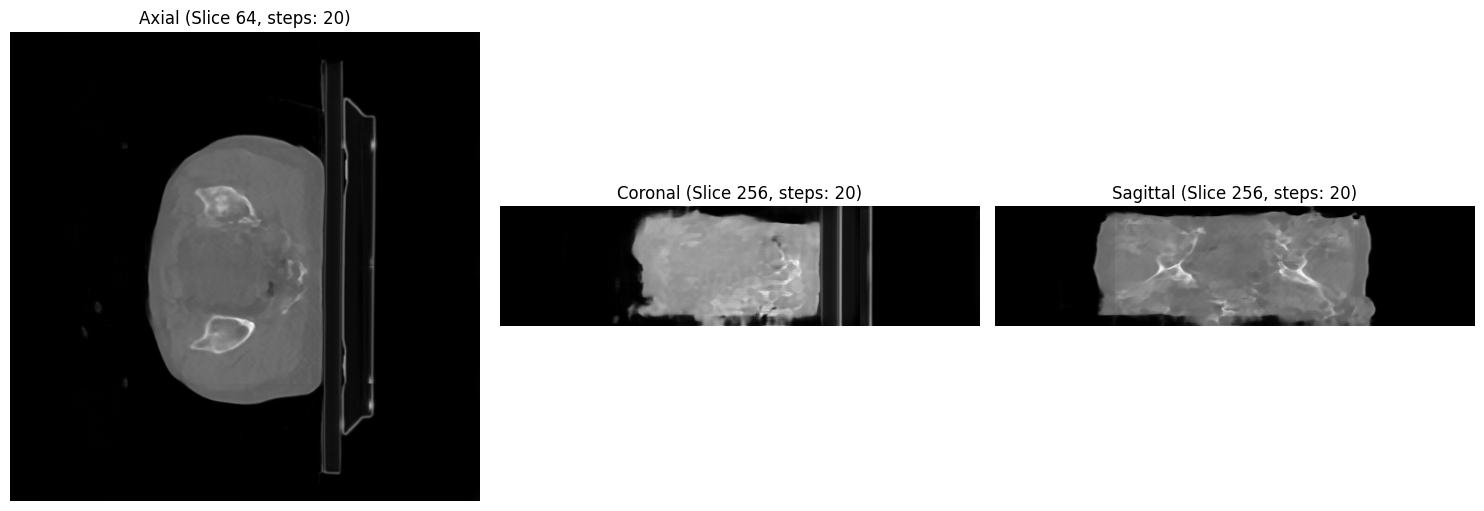

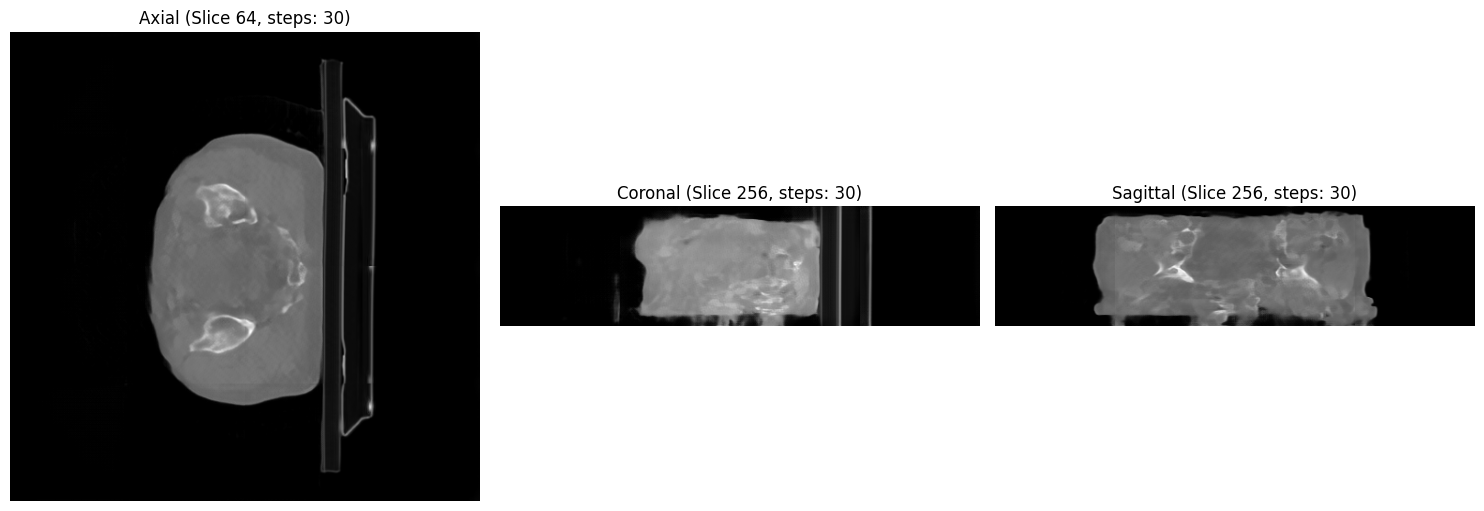

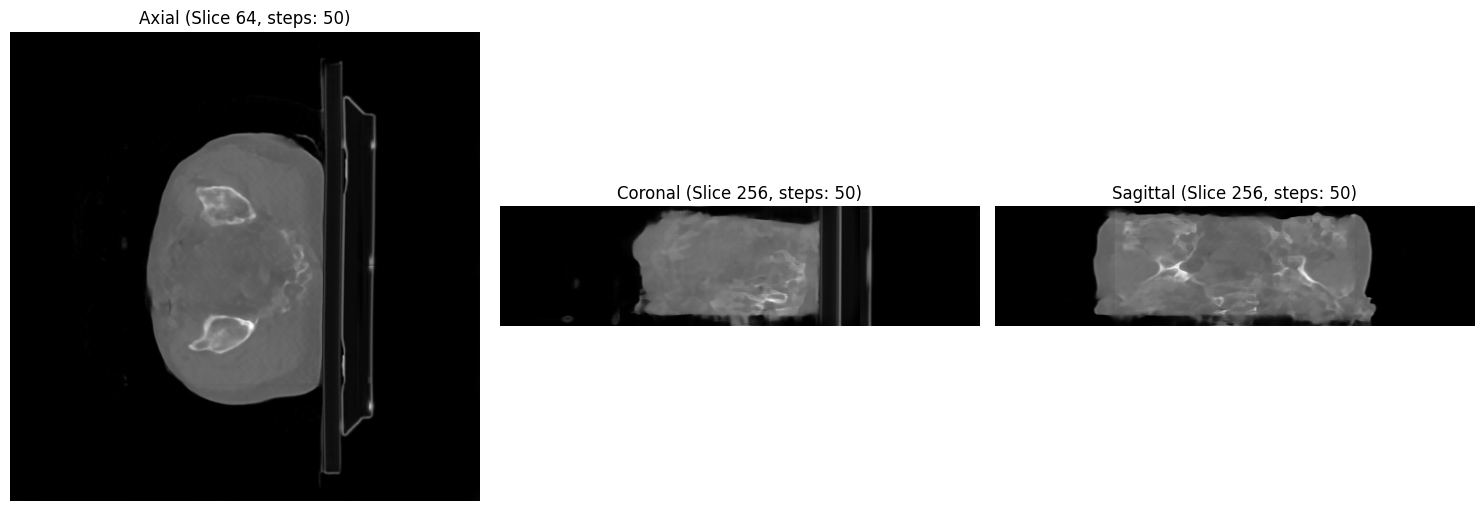

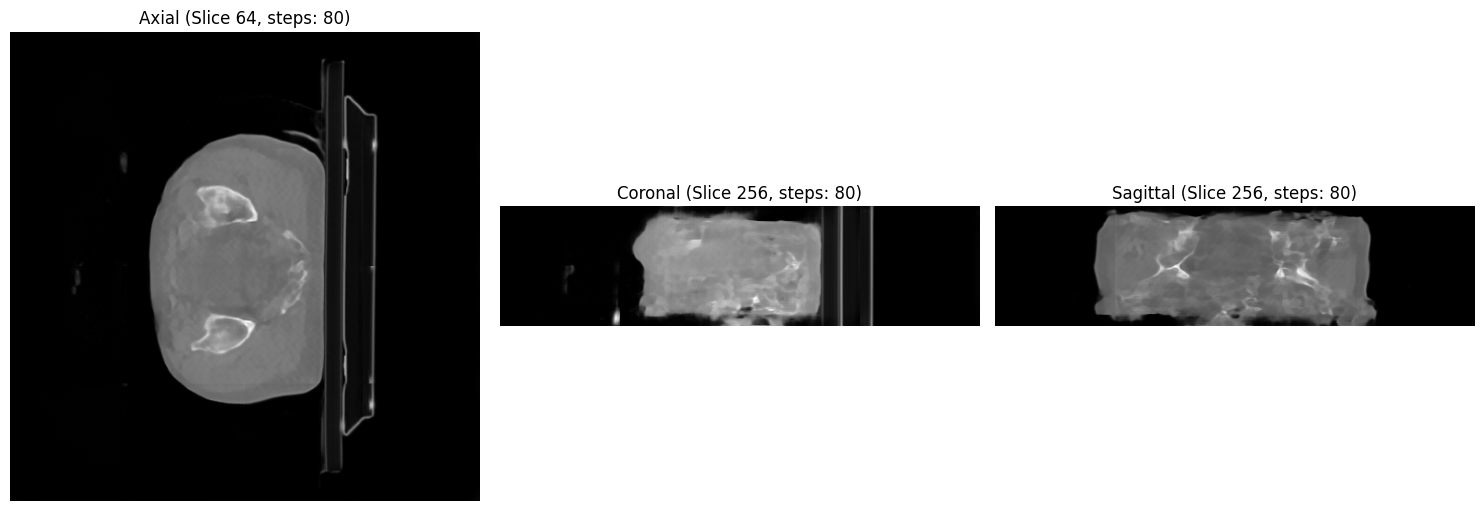

Generated vs Real:


,10,20,30,50,80
mae,36.642723,37.315743,38.368793,38.678475,38.170675
ssim,0.838859,0.835669,0.830169,0.829350,0.831411
psnr,26.626374,26.462312,26.274298,26.178934,26.285572
sob,493.081453,498.808461,510.888983,514.280286,509.131653
lpips,0.116400,0.117428,0.121481,0.122315,0.119727


Pairwise:


,10,20,30,50,80
mae,16.274663,17.153209,20.027820,19.878915,19.565037
ssim,0.937627,0.932645,0.917461,0.918318,0.919312
psnr,32.540259,31.853211,30.914749,30.978501,31.008776
sob,258.995286,270.417144,307.779641,303.760975,300.990239
lpips,0.037800,0.040152,0.048647,0.048822,0.045677


In [16]:
generated_vs_real_columns = []
pairwise_columns = []
for steps in NUMBER_OF_STEPS:
    out_dir = STEPS_OUTPUT_DIR / str(steps)

    # Create two series of summary metrics
    generated_vs_real_columns.append(
        get_mean_of_means(out_dir / "metrics" / "generated_vs_real_summary.csv", str(steps))
    )
    pairwise_columns.append(
        get_mean_of_means(out_dir / "metrics" / "generated_pairwise_variety_metrics_summary.csv", str(steps))
    )

    # Get a generated CT for the same patient in the first section
    generated_img = load_tensor(out_dir / "generated_ct" / "Patient_56" / "Patient_56_gen_1.pt")

    # Get middle indices for each axis
    idx_h, idx_w, idx_d = [s // 2 for s in generated_img.shape]

    # Create the plot
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Axial view (Top-down)
    axes[0].imshow(generated_img[:, :, idx_d].T, cmap="gray", origin="lower")
    axes[0].set_title(f"Axial (Slice {idx_d}, steps: {steps})")
    axes[0].axis("off")

    # Coronal view (Front-to-back)
    axes[1].imshow(generated_img[:, idx_w, :].T, cmap="gray", origin="lower")
    axes[1].set_title(f"Coronal (Slice {idx_w}, steps: {steps})")
    axes[1].axis("off")

    # Sagittal view (Side-to-side)
    axes[2].imshow(generated_img[idx_h, :, :].T, cmap="gray", origin="lower")
    axes[2].set_title(f"Sagittal (Slice {idx_h}, steps: {steps})")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

generated_vs_real_steps_df = pd.concat(generated_vs_real_columns, axis=1)
pairwise_steps_df = pd.concat(pairwise_columns, axis=1)

print("Generated vs Real:")
display(generated_vs_real_steps_df)
print("Pairwise:")
display(pairwise_steps_df)

The sweet spot is 30. It seems to be least prone to artifacts and results in highest pairwise diversity.